# River Water Quality Prediction Using Satellite and Ground Observations
### Computational Project Submission

**Vellore Institute of Technology**<br>
**Course:** Artificial Intelligence (BCSE306L)<br>
**Slot:** C1 + TC1<br>
**School / Campus:** ______________________________<br>
**Submission date:** ______________________________

| Team member | Registration number |
| :-- | :-- |
| ______________________________ | ______________________________ |
| ______________________________ | ______________________________ |
| ______________________________ | ______________________________ |
| ______________________________ | ______________________________ |

---

## Abstract

This study evaluates neural estimation of biochemical oxygen demand (BOD) from paired satellite and ground observations at selected River Ganga monitoring stations. A corpus of 100 observations is partitioned into 80 chronological training records and 20 familiar-station test records; 26 additional observations assess transfer to four unseen stations. Three architectures are examined: a four-input multilayer perceptron, a satellite-band-and-ratio perceptron, and a gated satellite-chemical fusion network. Evaluation includes a training-mean baseline, mean absolute error, root mean squared error, and R-squared. KernelSHAP provides local explanations, while a separate conditional physics-informed neural network approximates an assumed oxygen-balance system. The four-input model achieves familiar-station MAE of 0.185 mg/L. Fusion gives the lowest neural-model unseen-station MAE of 0.694 mg/L, but is outperformed by the training-mean baseline at 0.520 mg/L. Numerical oxygen agreement concerns the assumed equations rather than measured future conditions. The findings demonstrate a substantial spatial generalization gap and motivate broader independent validation.

**Keywords:** water quality; biochemical oxygen demand; Sentinel-2; neural regression; spatial generalization; KernelSHAP; physics-informed neural networks.

## Research objectives

1. Compare BOD regression using satellite-only and satellite-chemical inputs.
2. Assess performance separately at familiar and unseen monitoring stations.
3. Explain individual predictions with reference-dependent feature attributions.
4. Evaluate a conditional oxygen PINN against an analytical solution.
5. Verify consistency between executable inference and archived experimental results.

## Contents

1. Dataset description and observation matching
2. Experimental design and data partitioning
3. Model architectures and preprocessing
4. Checkpoint inference and prediction verification
5. Predictive performance and result analysis
6. Feature selection and ablation study
7. Local explanation analysis
8. Conditional oxygen-balance modelling
9. Discussion, limitations, and conclusion
10. Computational reproducibility
11. References

## Computational scope

This notebook reproduces inference and evaluates previously trained checkpoints. It does not retrain the models or recompute KernelSHAP values. Saved explanations are checked for additive reconstruction. Raw acquisition, training, and provenance are documented in the accompanying source repository [6]. BOD is expressed in mg/L and is not a complete drinking-water safety indicator.

---

### Environment and artifact initialization

The following cell resolves repository-local helper files, verifies the archived artifact bundle, and loads the saved models and cohorts. Package versions and data-integrity checks are reported in Section 10.


In [1]:
from pathlib import Path
import os
import sys
import json
import importlib.util

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'pyproject.toml').exists() and (p / 'demo_bundle').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Open the notebook from within the project checkout.')
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / 'tmp/notebook-matplotlib'))
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Resolve helper files explicitly to avoid collisions with generic package names.
def load_project_helper(filename):
    path = ROOT / 'scripts' / filename
    if not path.is_file():
        raise FileNotFoundError(f'Missing project helper: {path}. Open the complete project checkout.')
    spec = importlib.util.spec_from_file_location('river_submission_' + path.stem, path)
    if spec is None or spec.loader is None:
        raise ImportError(f'Cannot load project helper: {path}')
    module = importlib.util.module_from_spec(spec)
    try:
        spec.loader.exec_module(module)
    except ModuleNotFoundError as exc:
        raise ModuleNotFoundError(
            f'Project helper needs dependency {exc.name!r}. Notebook Python: {sys.executable}. '
            'Install requirements-notebook.txt in this environment and restart the kernel.'
        ) from exc
    return module

restore = load_project_helper('restore_demo_bundle.py').restore

artifact_count = restore(ROOT / 'demo_bundle', ROOT)
model_support = load_project_helper('three_model_support.py')
load, sha = model_support.load, model_support.sha
train, familiar, unseen, examples, models, source_hashes = load()
checkpoint_hashes = {name: sha(model['path']) for name, model in models.items()}
LABELS = {'selected_four_inputs': 'Four-input MLP', 'all_components': 'Fusion network',
          'satellite_ratios': 'Satellite ratios', 'training_mean': 'Training mean'}
PREFIX = {'selected_four_inputs': 'selected_four_inputs', 'all_components': 'network_all_components',
          'satellite_ratios': 'satellite_ratios', 'training_mean': 'training_mean'}
COHORTS = {'familiar_20': familiar, 'new_stations_strict_26': unseen}
RESULTS = ROOT / 'docs/saved_models_unseen_results'
saved_predictions = pd.read_csv(RESULTS / 'predictions.csv')
saved_metrics = pd.read_csv(RESULTS / 'metrics.csv')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.constrained_layout.use': True})
pd.set_option('display.max_columns', 14)
pd.set_option('display.precision', 4)
print(f'Artifact initialization complete: {artifact_count} verified files and three hash-verified BOD checkpoints.')


Artifact initialization complete: 249 verified files and three hash-verified BOD checkpoints.


## 1. Dataset Description and Observation Matching

The original corpus has **100 matched observations from three Ganga stations**, dated 25 November 2018 to 28 December 2021. CPCB monitoring records provide measured BOD and chemical inputs [1]. Sentinel-2 SR Harmonized provides ten reflectance bands [2].

Extraction uses a 60 m neighbourhood on a common 20 m grid; the temporal search is first +/-3 days and then +/-7 days. Cloud, water, coverage, and valid-pixel thresholds filter the extraction. These checks do not prove the satellite and laboratory sample describe identical conditions.

Measured BOD is the supervised target and is excluded from all BOD-model input frames. Coordinates, dates, identifiers, and extraction-quality fields provide traceability. Table 1 reports station coverage, Table 2 illustrates matched observations, and Table 3 summarizes the measured variables. Optional total coliform is missing in 71 original records and is excluded from these models.


In [2]:
paired = pd.read_csv(ROOT / 'outputs/india_100_chemical_dataset_20261014/paired.csv')
assert len(paired) == 100 and paired.observation_id.is_unique
display(Markdown('**Table 1. Original matched-observation counts by monitoring station.**'))
display(paired.groupby('station_name').size().rename('Matched observations').to_frame())
display(Markdown('**Table 2. Sample ground-satellite pairs and extraction metadata.**'))
display(paired[['station_name', 'sample_date', 'satellite_local_date', 'temporal_offset_days',
                'cloud_fraction', 'water_fraction', 'coverage_fraction', 'pixel_count',
                'ground_bod', 'ground_fecal_coliform', 'ground_ph', 'ground_dissolved_oxygen']].head(6))
display(Markdown('**Table 3. Descriptive statistics of the original 100 observations.**'))
display(paired[['ground_bod', 'ground_fecal_coliform', 'ground_ph',
                'ground_dissolved_oxygen', 'temporal_offset_days']].describe().loc[['min', 'max', 'mean']])
print('BOD and DO: mg/L. Fecal coliform: MPN/100 mL. pH and reflectance: unitless.')


**Table 1. Original matched-observation counts by monitoring station.**

,Matched observations
station_name,
GANGA AT VARANASI D/S (MALVIYA BRIDGE) U.P,37
GANGA U/S ANOOPSHAHAR,38
RIVER GANGA AT MADHYA GANGA BARRAGE BIJNOR,25


**Table 2. Sample ground-satellite pairs and extraction metadata.**

,station_name,sample_date,satellite_local_date,temporal_offset_days,cloud_fraction,water_fraction,coverage_fraction,pixel_count,ground_bod,ground_fecal_coliform,ground_ph,ground_dissolved_oxygen
0,GANGA U/S ANOOPSHAHAR,2018-11-25,2018-11-26,1,0.0,1.0000,1.0,30,2.8,310.0,7.4,9.8
1,GANGA U/S ANOOPSHAHAR,2018-12-08,2018-12-08,0,0.0,1.0000,1.0,30,2.6,250.0,7.5,9.7
2,GANGA U/S ANOOPSHAHAR,2019-01-14,2019-01-12,-2,0.0,1.0000,1.0,30,2.4,230.0,7.4,10.4
3,GANGA U/S ANOOPSHAHAR,2019-02-07,2019-02-09,2,0.0,0.6667,1.0,20,1.5,280.0,7.2,9.5
4,GANGA U/S ANOOPSHAHAR,2019-03-04,2019-03-06,2,0.0,0.6333,1.0,19,1.2,250.0,7.3,9.9
5,GANGA U/S ANOOPSHAHAR,2019-06-20,2019-06-21,1,0.0,0.7000,1.0,21,2.3,220.0,7.5,8.0


**Table 3. Descriptive statistics of the original 100 observations.**

,ground_bod,ground_fecal_coliform,ground_ph,ground_dissolved_oxygen,temporal_offset_days
min,0.900,110.0,6.8000,6.200,-7.00
max,4.100,23000.0,8.7000,10.800,7.00
mean,2.266,4894.8,7.7456,8.282,-0.37


BOD and DO: mg/L. Fecal coliform: MPN/100 mL. pH and reflectance: unitless.


## 2. Experimental Design and Data Partitioning

The oldest **80** original observations train the models; the newest **20** evaluate familiar-station performance. Scaling and station chemistry profiles use training data only. The familiar test cases have been inspected during development, so they are not an untouched final validation set.

Four new stations provide 30 observations. Four with satellite acquisitions overlapping training are excluded, leaving **26 strict unseen observations**. This is a retrospective station-transfer test, not a future-period forecast. The 30-row pre-exclusion cohort is not mixed into the strict comparison.


In [3]:
from river_water_quality.training.splits import acquisition_group

assert len(train) == 80 and len(familiar) == 20 and len(unseen) == 26
assert not set(train.observation_id) & set(familiar.observation_id)
assert not set(train.station_id) & set(unseen.station_id)
assert not set(train.scene_id.map(acquisition_group)) & set(unseen.scene_id.map(acquisition_group))
assert pd.to_datetime(train.sample_date).max() < pd.to_datetime(familiar.sample_date).min()
audit = []
for label, frame in [('Train', train), ('Familiar test', familiar), ('Strict unseen test', unseen)]:
    audit.append({'Cohort': label, 'Rows': len(frame), 'Stations': frame.station_id.nunique(),
                  'First date': frame.sample_date.min(), 'Last date': frame.sample_date.max()})
display(Markdown('**Table 4. Chronological training and evaluation cohort definitions.**'))
display(pd.DataFrame(audit).set_index('Cohort'))
display(Markdown('**Table 5. Strict unseen-station observation counts.**'))
display(unseen.groupby('station_name').size().rename('Strict unseen observations').to_frame())
print('Partition checks satisfied: disjoint train/test observations, unseen station identities, and strict acquisition separation.')


**Table 4. Chronological training and evaluation cohort definitions.**

,Rows,Stations,First date,Last date
Cohort,,,,
Train,80,3,2018-11-25,2021-07-15
Familiar test,20,3,2021-09-15,2021-12-28
Strict unseen test,26,4,2020-08-31,2021-12-21


**Table 5. Strict unseen-station observation counts.**

,Strict unseen observations
station_name,
GANGA AT ALLAHABAD D/S (SANGAM) U.P.,7
GANGA AT GARHMUKTESHWAR U.P,7
GANGA AT NARORA (BULANDSAHAR) U.P.,9
GANGA U/S VINDHYACHAL MIRZAPUR,3


Partition checks satisfied: disjoint train/test observations, unseen station identities, and strict acquisition separation.


## 3. Model Architectures and Preprocessing

Three input configurations assess the trade-off between measurement availability and predictive performance. The first two models use scikit-learn MLP regression with L-BFGS optimization, alpha 1, maximum 3,000 iterations, and random seed 42 [3, 6]. Input and target scalers are fitted on training data only; fecal coliform undergoes a log1p transformation. Predictions are transformed back to BOD units and clipped to non-negative values.

The fusion model uses independent tanh branches and a date-dependent sigmoid gate. Its non-negativity penalty and gradient-reversal station classifier operate during training. Station identity is not an inference feature. Figures 1-3 document the architectures and preprocessing pathways. The oxygen PINN in Section 8 is a separate downstream model.


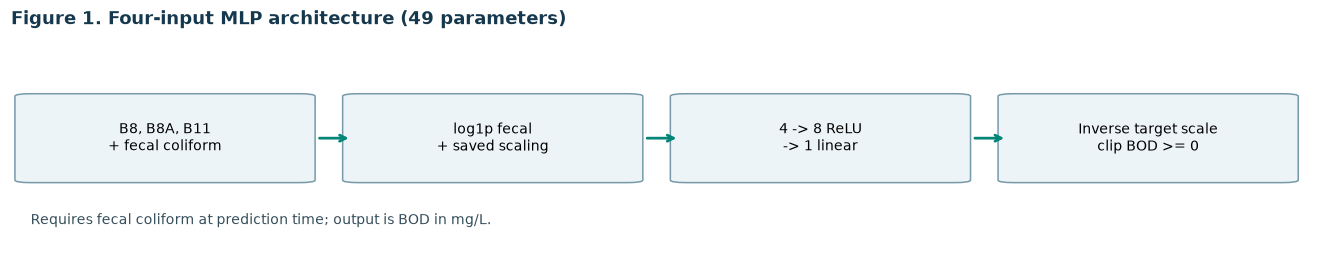

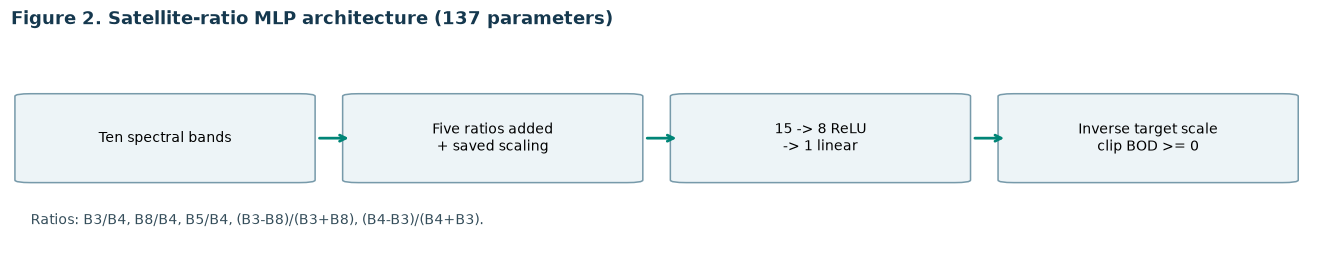

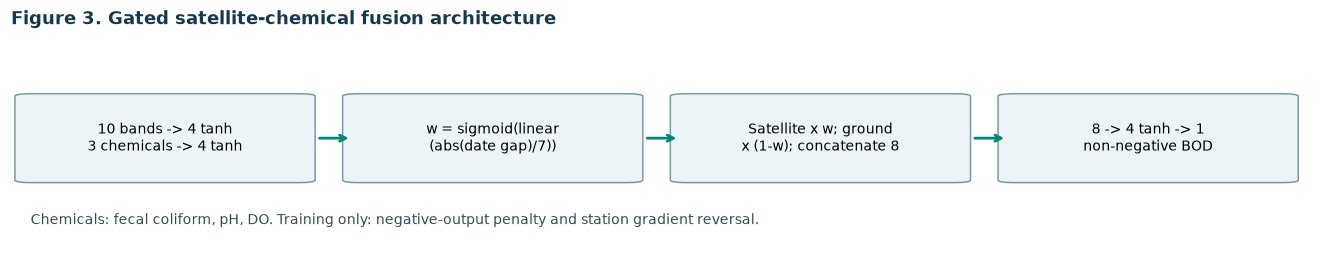

In [4]:
from matplotlib.patches import FancyBboxPatch

def architecture(title, stages, note):
    fig, ax = plt.subplots(figsize=(12, 2.2))
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
    width = 0.205
    for i, text in enumerate(stages):
        x = 0.015 + i * 0.25
        ax.add_patch(FancyBboxPatch((x, 0.30), width, 0.40, boxstyle='round,pad=0.012',
                                   facecolor='#edf4f7', edgecolor='#779aaa'))
        ax.text(x + width/2, 0.50, text, ha='center', va='center', fontsize=9)
        if i < len(stages)-1:
            ax.annotate('', xy=(x+0.245, .50), xytext=(x+width+.013, .50),
                        arrowprops={'arrowstyle': '->', 'color': '#008577', 'lw': 1.8})
    ax.set_title(title, loc='left', fontweight='bold', color='#15384e')
    ax.text(.015, .09, note, fontsize=9, color='#344d5a')
    plt.show()

architecture('Figure 1. Four-input MLP architecture (49 parameters)',
             ['B8, B8A, B11\n+ fecal coliform', 'log1p fecal\n+ saved scaling',
              '4 -> 8 ReLU\n-> 1 linear', 'Inverse target scale\nclip BOD >= 0'],
             'Requires fecal coliform at prediction time; output is BOD in mg/L.')
architecture('Figure 2. Satellite-ratio MLP architecture (137 parameters)',
             ['Ten spectral bands', 'Five ratios added\n+ saved scaling',
              '15 -> 8 ReLU\n-> 1 linear', 'Inverse target scale\nclip BOD >= 0'],
             'Ratios: B3/B4, B8/B4, B5/B4, (B3-B8)/(B3+B8), (B4-B3)/(B4+B3).')
architecture('Figure 3. Gated satellite-chemical fusion architecture',
             ['10 bands -> 4 tanh\n3 chemicals -> 4 tanh', 'w = sigmoid(linear\n(abs(date gap)/7))',
              'Satellite x w; ground\nx (1-w); concatenate 8', '8 -> 4 tanh -> 1\nnon-negative BOD'],
             'Chemicals: fecal coliform, pH, DO. Training only: negative-output penalty and station gradient reversal.')


## 4. Checkpoint Inference and Prediction Verification

One observation from the archived explanation subset is selected for a consistent case study across prediction, attribution, and oxygen analysis. The subset comprises one observation from each of three familiar and four unseen stations (Table 6). The same observation identifier is used in Sections 4, 7, and 8.

Inputs are restricted to the saved model feature definitions. The target is kept outside each inference frame. Live predictions are compared with their frozen counterparts.


In [5]:
display(Markdown('**Table 6. Observations available for matched local-explanation analysis.**'))
display(examples[['observation_id', 'station_name', 'sample_date', 'cohort']])
OBSERVATION_ID = str(examples.iloc[0].observation_id)
selected = examples.set_index('observation_id').loc[[OBSERVATION_ID]].reset_index()
selected_row = selected.iloc[0]
saved_case = saved_predictions[saved_predictions.observation_id.eq(OBSERVATION_ID)].iloc[0]
live_values = {}
rows = []
for name, model in models.items():
    inputs = selected[model['features']].copy()
    assert 'ground_bod' not in inputs and 'observation_id' not in inputs
    value = float(model['predict'](inputs)[0])
    live_values[name] = value
    frozen = float(saved_case[PREFIX[name] + '_bod_mg_l'])
    np.testing.assert_allclose(value, frozen, atol=1e-5, rtol=1e-5)
    rows.append({'Model': LABELS[name], 'Measured BOD': selected_row.ground_bod,
                 'Recomputed BOD': value, 'Archived BOD': frozen,
                 'Absolute error': abs(value-selected_row.ground_bod)})
display(Markdown(f'**Case-study observation:** {selected_row.station_name}, {selected_row.sample_date}'))
display(Markdown('**Table 7. Recomputed and archived case-study predictions (mg/L).**'))
display(pd.DataFrame(rows).set_index('Model'))
print('Prediction verification satisfied for all three checkpoints (absolute/relative tolerance 1e-5).')


**Table 6. Observations available for matched local-explanation analysis.**

,observation_id,station_name,sample_date,cohort
0,cpcb-02b0a00ca59c5b55-383,GANGA AT VARANASI D/S (MALVIYA BRIDGE) U.P,2021-09-15,familiar
1,cpcb-02b0a00ca59c5b55-980,RIVER GANGA AT MADHYA GANGA BARRAGE BIJNOR,2021-09-28,familiar
2,cpcb-02b0a00ca59c5b55-476,GANGA U/S ANOOPSHAHAR,2021-10-11,familiar
3,cpcb-02b0a00ca59c5b55-196,GANGA AT GARHMUKTESHWAR U.P,2021-11-19,unseen
4,cpcb-02b0a00ca59c5b55-106,GANGA AT ALLAHABAD D/S (SANGAM) U.P.,2021-10-31,unseen
5,cpcb-02b0a00ca59c5b55-338,GANGA AT NARORA (BULANDSAHAR) U.P.,2021-12-21,unseen
6,cpcb-02b0a00ca59c5b55-501,GANGA U/S VINDHYACHAL MIRZAPUR,2021-11-08,unseen


**Case-study observation:** GANGA AT VARANASI D/S (MALVIYA BRIDGE) U.P, 2021-09-15

**Table 7. Recomputed and archived case-study predictions (mg/L).**

,Measured BOD,Recomputed BOD,Archived BOD,Absolute error
Model,,,,
Four-input MLP,3.7,3.3889,3.3889,0.3111
Fusion network,3.7,3.3479,3.3479,0.3521
Satellite ratios,3.7,3.3329,3.3329,0.3671


Prediction verification satisfied for all three checkpoints (absolute/relative tolerance 1e-5).


## 5. Predictive Performance and Result Analysis

All three models are rerun on the same 46 evaluation observations. MAE, RMSE, and R-squared are recomputed from the resulting rows and checked against the frozen metric table. The baseline predicts the mean of the 80 training BOD targets for every case.

For measured values y and predictions y-hat, MAE = mean(abs(y-hat - y)), RMSE = sqrt(mean((y-hat - y)^2)), and R-squared = 1 - sum((y-hat - y)^2) / sum((y - mean(y))^2).

Lower MAE/RMSE is better. A negative R-squared means worse squared error than predicting that evaluation cohort's own mean; the training-mean baseline uses only training targets. Table 8 reports the recomputed results, Figure 4 compares MAE, and Figure 5 examines prediction distributions.


**Table 8. Recomputed cohort performance: MAE/RMSE in mg/L; R-squared unitless.**

n     mae    rmse      r2
Cohort                 Model                                       
familiar_20            Four-input MLP    20  0.1852  0.2368  0.9470
                       Fusion network    20  0.2827  0.3652  0.8741
                       Satellite ratios  20  0.5911  0.7343  0.4907
                       Training mean     20  1.0054  1.0440 -0.0293
new_stations_strict_26 Four-input MLP    26  0.7548  0.9244 -1.8088
                       Fusion network    26  0.6937  0.8932 -1.6224
                       Satellite ratios  26  0.9531  1.0848 -2.8680
                       Training mean     26  0.5197  0.6266 -0.2907

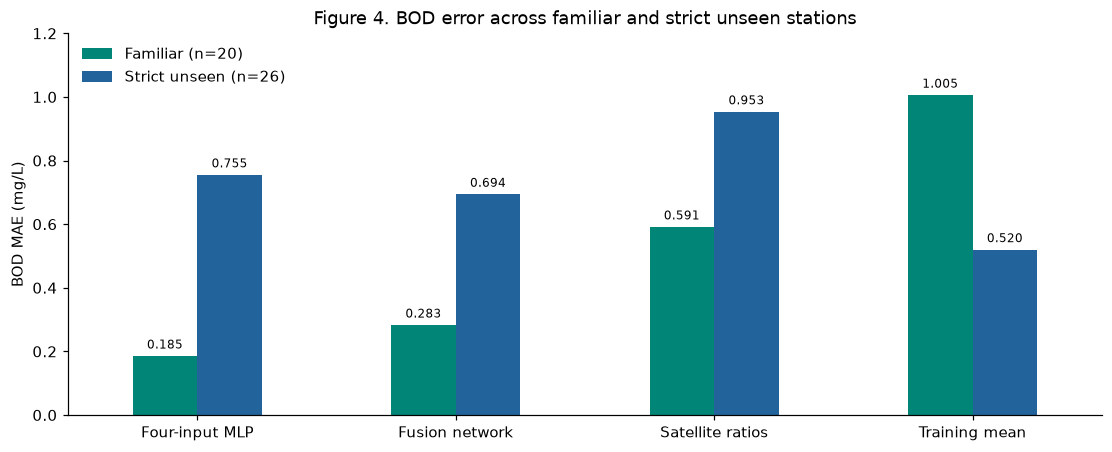

Evaluation verification satisfied: 46 observations per model and all reported metrics reproduce archived results.


In [6]:
def metrics(actual, predicted):
    actual, predicted = np.asarray(actual, float), np.asarray(predicted, float)
    error = predicted-actual
    return {'mae': np.abs(error).mean(), 'rmse': np.sqrt(np.mean(error**2)),
            'r2': 1-np.sum(error**2)/np.sum((actual-actual.mean())**2)}

evaluation = []
live_cohorts = {}
for cohort, frame in COHORTS.items():
    live_cohorts[cohort] = {}
    frozen_rows = saved_predictions[saved_predictions.cohort.eq(cohort)].set_index('observation_id').loc[frame.observation_id]
    for name in [*models, 'training_mean']:
        yhat = (np.full(len(frame), train.ground_bod.mean()) if name=='training_mean'
                else np.asarray(models[name]['predict'](frame[models[name]['features']].copy())))
        live_cohorts[cohort][name] = yhat
        np.testing.assert_allclose(yhat, frozen_rows[PREFIX[name]+'_bod_mg_l'], atol=1e-5, rtol=1e-5)
        result = metrics(frame.ground_bod, yhat)
        frozen_metric = saved_metrics[saved_metrics.cohort.eq(cohort) & saved_metrics.model.eq(PREFIX[name])].iloc[0]
        for metric, value in result.items():
            np.testing.assert_allclose(value, frozen_metric[metric], atol=1e-5, rtol=1e-5)
        evaluation.append({'Cohort': cohort, 'Model': LABELS[name], 'n': len(frame), **result})
evaluation = pd.DataFrame(evaluation)
display(Markdown('**Table 8. Recomputed cohort performance: MAE/RMSE in mg/L; R-squared unitless.**'))
display(evaluation.set_index(['Cohort', 'Model']))
chart = evaluation.pivot(index='Model', columns='Cohort', values='mae').reindex(list(LABELS.values()))
ax = chart.plot.bar(figsize=(10, 4), color=['#008577', '#22639b'], rot=0)
ax.set_ylabel('BOD MAE (mg/L)'); ax.set_xlabel(''); ax.set_title('Figure 4. BOD error across familiar and strict unseen stations')
ax.legend(['Familiar (n=20)', 'Strict unseen (n=26)'], frameon=False)
for bars in ax.containers: ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=8)
ax.set_ylim(0, 1.2); plt.show()
print('Evaluation verification satisfied: 46 observations per model and all reported metrics reproduce archived results.')


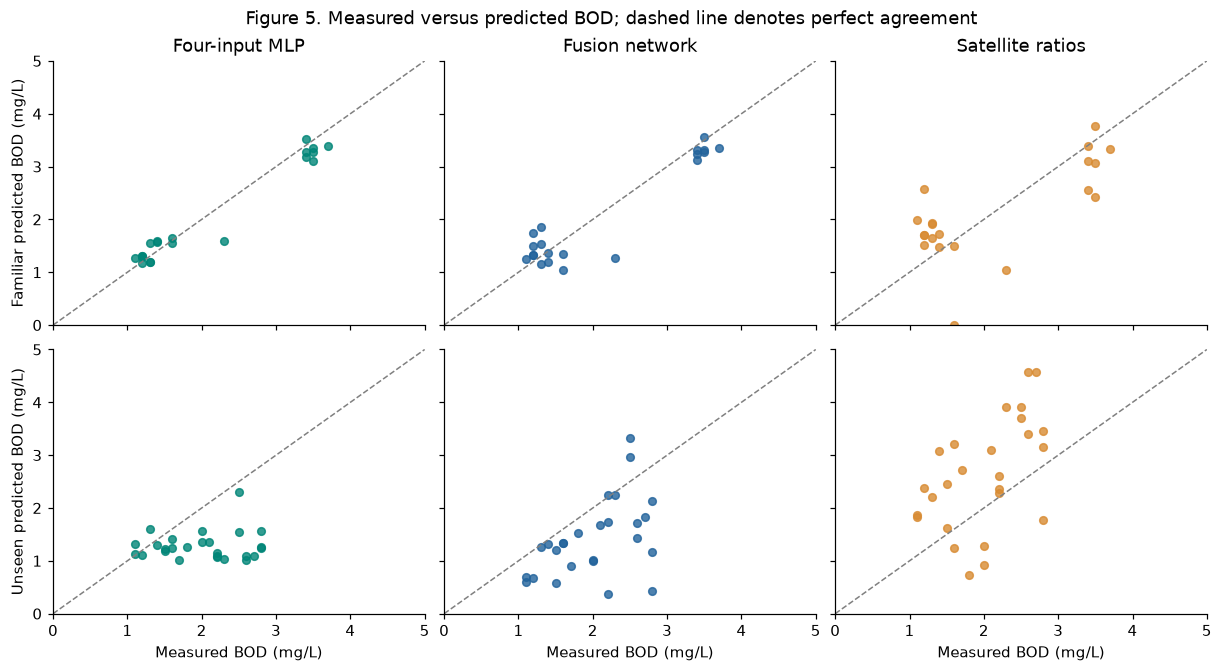

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharex=True, sharey=True)
fig.suptitle('Figure 5. Measured versus predicted BOD; dashed line denotes perfect agreement')
for r, (cohort, frame) in enumerate(COHORTS.items()):
    for col, name in enumerate(models):
        ax = axes[r, col]
        ax.scatter(frame.ground_bod, live_cohorts[cohort][name], s=25, alpha=.8,
                   color=['#008577', '#22639b', '#d88b32'][col])
        ax.plot([0, 5], [0, 5], '--', color='gray', linewidth=1)
        ax.set(xlim=(0,5), ylim=(0,5))
        if r==0: ax.set_title(LABELS[name])
        if r==1: ax.set_xlabel('Measured BOD (mg/L)')
        if col==0: ax.set_ylabel(('Familiar' if r==0 else 'Unseen')+' predicted BOD (mg/L)')
plt.show()


**Interpretation.** The four-input model achieves familiar MAE **0.185 mg/L** and R-squared **0.947**. Fusion has the lowest neural-model unseen MAE, **0.694 mg/L**, but the training mean is better at **0.520 mg/L**. The satellite-ratio model's lower input burden does not compensate for its larger errors in this experiment. These results do not establish broad river-transfer accuracy.


## 6. Feature Selection and Ablation Study

The compact input selection uses a split inside the 80 training observations, then refits the chosen model on all 80. The outer test answers do not choose its four features. Feature ranking remains dataset-specific.

The five archived fusion variants isolate the baseline architecture, date gate, non-negativity constraint, station-adversarial objective, and their combination. Tables 9-11 record feature rankings, leading validation candidates, and variant MAE. Figure 6 compares ablations under identical evaluation cohorts.


**Table 9. Training-subset feature ranking and selected inputs.**

,feature,modality,score,selected
0,ground_fecal_coliform,ground,0.8557,True
1,ground_ph,ground,0.7349,False
2,satellite_B8A,satellite,0.5498,True
3,satellite_B8,satellite,0.5459,True
4,satellite_B11,satellite,0.5357,True
5,satellite_B7,satellite,0.5286,False
6,satellite_B6,satellite,0.5067,False
7,satellite_B12,satellite,0.4864,False
8,ground_dissolved_oxygen,ground,0.4571,False
9,satellite_B5,satellite,0.3645,False


**Table 10. Five leading feature candidates by internal validation MAE.**

,candidate,input_count,validation_mae,selected
1,top3_bands_top1_ground,4,0.3568,True
11,top10_bands_top3_ground,13,0.3617,False
5,top5_bands_top1_ground,6,0.3727,False
9,top10_bands_top1_ground,11,0.4022,False
2,top3_bands_top2_ground,5,0.4226,False


**Table 11. Fusion ablation MAE by evaluation cohort (mg/L).**

cohort,familiar_20,new_stations_strict_26
model,,
network_baseline,0.3211,1.1163
network_gate_only,0.2799,0.6925
network_constraint_only,0.3221,1.1176
network_station_adversarial_only,0.3252,1.0971
network_all_components,0.2827,0.6937


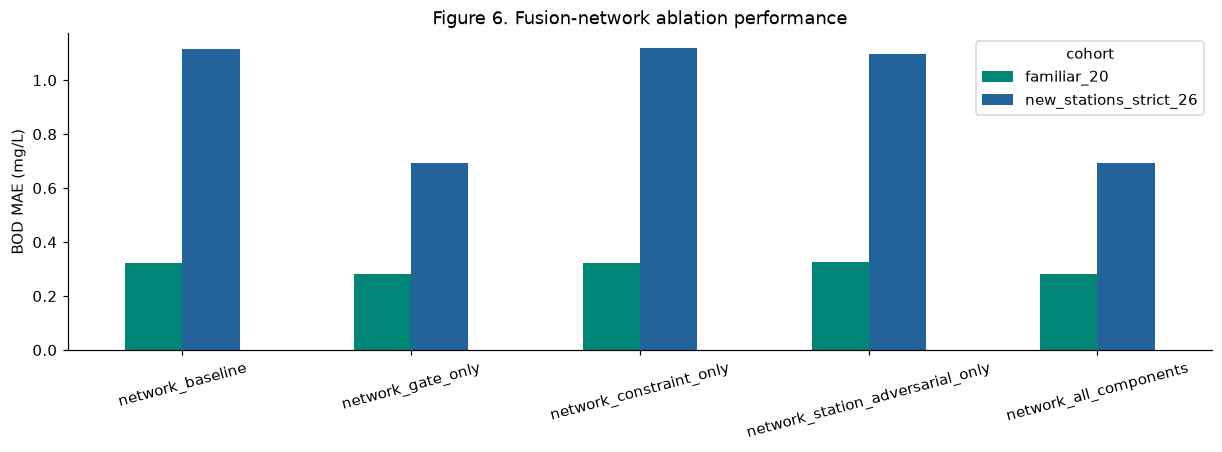

In [8]:
demos = ROOT / 'outputs/straightforward_demos_20261014'
ranking = pd.read_csv(demos / 'feature_ranking.csv')
candidates = pd.read_csv(demos / 'feature_candidates.csv')
display(Markdown('**Table 9. Training-subset feature ranking and selected inputs.**'))
display(ranking[['feature', 'modality', 'score', 'selected']])
display(Markdown('**Table 10. Five leading feature candidates by internal validation MAE.**'))
display(candidates[['candidate', 'input_count', 'validation_mae', 'selected']].sort_values('validation_mae').head(5))
variants = ['network_baseline', 'network_gate_only', 'network_constraint_only',
            'network_station_adversarial_only', 'network_all_components']
ablation = saved_metrics[saved_metrics.cohort.isin(COHORTS) & saved_metrics.model.isin(variants)]
display(Markdown('**Table 11. Fusion ablation MAE by evaluation cohort (mg/L).**'))
display(ablation.pivot(index='model', columns='cohort', values='mae').reindex(variants))
ax = ablation.pivot(index='model', columns='cohort', values='mae').reindex(variants).plot.bar(
    figsize=(11,4), color=['#008577','#22639b'], rot=15)
ax.set_ylabel('BOD MAE (mg/L)'); ax.set_xlabel(''); ax.set_title('Figure 6. Fusion-network ablation performance')
plt.show()


**Interpretation.** Gate-only performs slightly better than all-components on both cohorts. Constraint-only and adversarial-only do not establish an accuracy gain. No repeated-seed uncertainty estimate is available, so the small gap between gate-only and all-components should not be overstated. The non-negativity penalty is distinct from the separate oxygen PINN.


## 7. Local Explanation Analysis

Each model has seven saved cases: three familiar and four unseen. KernelSHAP explanations use 20 training-background rows, seed 42, and 512 samples [4, 6]. Satellite ratios are recomputed from masked raw bands rather than treated as independent raw measurements.

Figure 7 shows signed contributions for the case-study observation, and Table 12 groups them by modality. Reference plus contributions reconstructs predicted BOD. Contributions are background-dependent local explanations; they do not establish causality or global feature importance.


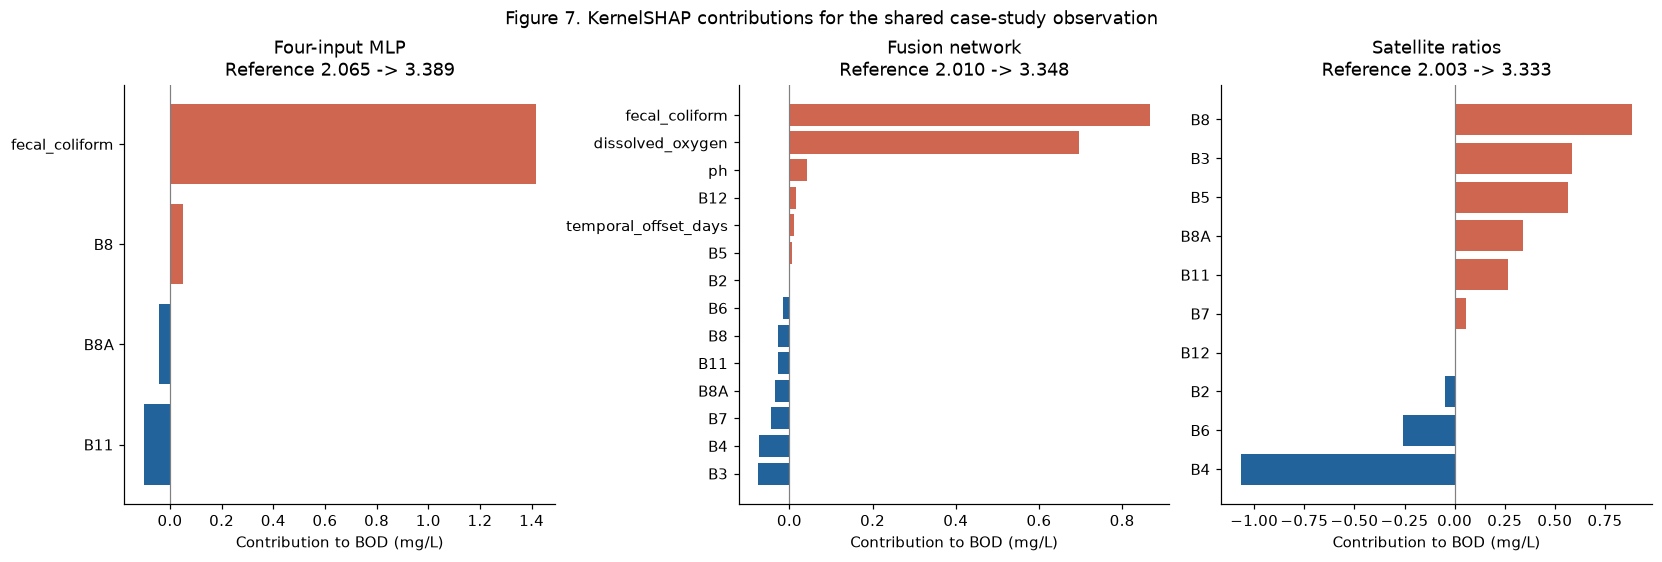

**Table 12. Reference values and modality-level BOD contributions (mg/L).**

,Reference,Satellite,Ground,Date gap,Prediction
Model,,,,,
Four-input MLP,2.0652,-0.0915,1.4151,0.0000,3.3889
Fusion network,2.0104,-0.2794,1.6057,0.0112,3.3479
Satellite ratios,2.0032,1.3297,0.0000,0.0000,3.3329


Attribution verification satisfied: 21 reconstructions and three case-study predictions agree within tolerance.


In [9]:
shap_dir = ROOT / 'docs/three_model_shap_results'
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Figure 7. KernelSHAP contributions for the shared case-study observation')
shap_summary = []
for ax, name in zip(axes, models):
    frame = pd.read_csv(shap_dir / f'{name}_explanations.csv')
    assert len(frame)==7 and frame.observation_id.is_unique
    cols = [c for c in frame if c.startswith('shap_')]
    np.testing.assert_allclose(frame.reference_bod_mg_l + frame[cols].sum(axis=1),
                               frame.predicted_bod_mg_l, atol=1e-5)
    case = frame.set_index('observation_id').loc[OBSERVATION_ID]
    np.testing.assert_allclose(case.predicted_bod_mg_l, live_values[name], atol=1e-5)
    values = case[cols].astype(float).sort_values()
    labels = [c.removeprefix('shap_').replace('satellite_', '').replace('ground_', '') for c in values.index]
    ax.barh(labels, values, color=['#22639b' if v<0 else '#cf6650' for v in values])
    ax.axvline(0, color='gray', lw=.8); ax.set_xlabel('Contribution to BOD (mg/L)')
    ax.set_title(LABELS[name]+f'\nReference {case.reference_bod_mg_l:.3f} -> {case.predicted_bod_mg_l:.3f}')
    shap_summary.append({'Model': LABELS[name], 'Reference': case.reference_bod_mg_l,
                         'Satellite': case.satellite_contribution_mg_l,
                         'Ground': case.ground_contribution_mg_l,
                         'Date gap': case.date_gap_contribution_mg_l,
                         'Prediction': case.predicted_bod_mg_l})
plt.show()
display(Markdown('**Table 12. Reference values and modality-level BOD contributions (mg/L).**'))
display(pd.DataFrame(shap_summary).set_index('Model'))
print('Attribution verification satisfied: 21 reconstructions and three case-study predictions agree within tolerance.')


## 8. Conditional Oxygen-Balance Modelling

The conditional network is **3 inputs -> 24 tanh -> 24 tanh -> 2 outputs**, with hard initial conditions. Inputs encode time, ultimate oxygen demand, and measured initial DO. It predicts remaining demand and DO over 0-5 days.

The assumed equations are dL/dt = -kD L and dO/dt = kR(Cs-O)-kD L. Fixed values are kD=0.23/day, kR=0.50/day, and Cs=8.26 mg/L. Predicted BOD is treated as BOD5, with L0=BOD5/(1-exp(-5 kD)). Training follows the physics-informed principle of penalizing equation residuals [5]; this implementation uses Adam for 1,500 epochs, seed 42, and a non-negativity penalty [6]. It does not fit measured future trajectories.

Measured initial DO is required for every oxygen scenario, including those driven by satellite-only BOD estimates. Figure 8 compares PINN and analytical trajectories. Table 13 reports case-study equation errors and extrapolation status; Table 14 summarizes archived cohort-level equation error.


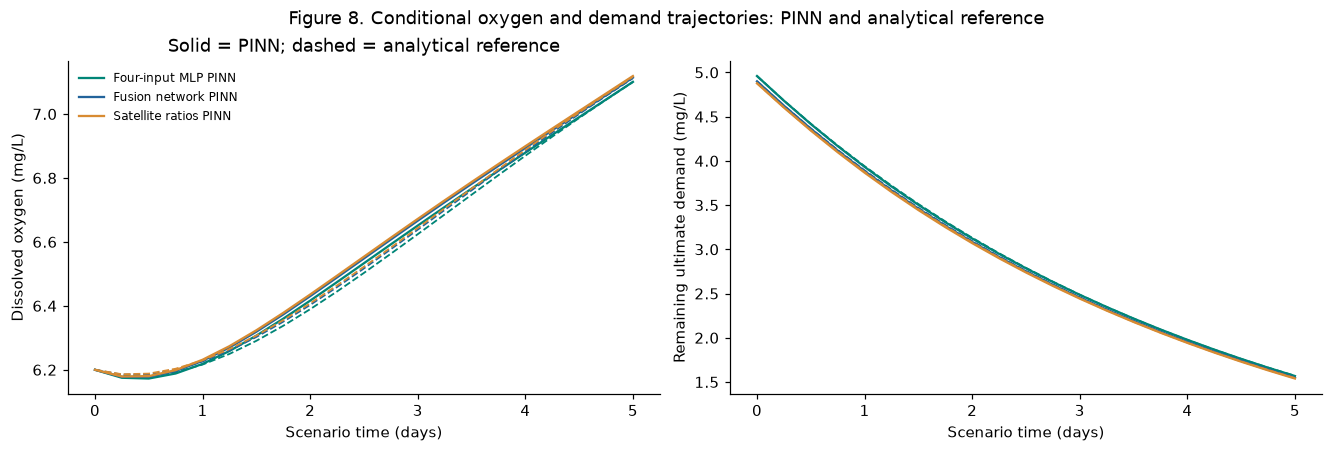

**Table 13. Case-study oxygen-solver error and extrapolation status.**

,BOD5 mg/L,Initial DO mg/L,Equation MAE mg/L,Extrapolation
Scenario,,,,
Four-input MLP,3.3889,6.2,0.0136,True
Fusion network,3.3479,6.2,0.0144,True
Satellite ratios,3.3329,6.2,0.0147,True


**Table 14. Archived oxygen-solver error by BOD source and cohort (mg/L).**

,model,cohort,initial_conditions,time_points_per_condition,oxygen_solver_mae_mg_l,maximum_oxygen_solver_error_mg_l,negative_predicted_oxygen_points
0,all_components,familiar_20,20,21,0.0071,0.0312,0
1,all_components,unseen_strict_26,26,21,0.0099,0.0306,0
2,satellite_ratios,familiar_20,20,21,0.0084,0.0354,0
3,satellite_ratios,unseen_strict_26,26,21,0.0111,0.0593,0
4,selected_four_inputs,familiar_20,20,21,0.0070,0.0303,0
5,selected_four_inputs,unseen_strict_26,26,21,0.0088,0.0282,0


Assumptions: kD=0.23/day, kR=0.5/day, saturation=8.26 mg/L. Initial conditions checked.


In [10]:
import torch
from river_water_quality.training.oxygen_pinn import predict as oxygen_predict, analytical, initial_demand, KD, KR, CS

oxygen_dir = ROOT / 'docs/oxygen_pinn_results'
oxygen_path = oxygen_dir / 'oxygen_pinn.pt'
oxygen_hash = sha(oxygen_path)
oxygen_provenance = json.loads((oxygen_dir / 'provenance.json').read_text())
assert oxygen_hash == oxygen_provenance['model_sha256'], 'Oxygen checkpoint hash mismatch'
checkpoint = torch.load(oxygen_path, map_location='cpu', weights_only=True)
t = np.linspace(0, 5, 21)
o0 = float(selected_row.ground_dissolved_oxygen)
fig, axes = plt.subplots(1,2,figsize=(12,4))
fig.suptitle('Figure 8. Conditional oxygen and demand trajectories: PINN and analytical reference')
oxygen_checks = []
for color, (name, bod) in zip(['#008577','#22639b','#d88b32'], live_values.items()):
    curve = oxygen_predict(checkpoint, t, bod, o0)
    demand_ref, do_ref = analytical(t, initial_demand(bod), o0)
    np.testing.assert_allclose(curve[0], [initial_demand(bod), o0], atol=1e-5)
    for ax, values, ref in [(axes[0],curve[:,1],do_ref),(axes[1],curve[:,0],demand_ref)]:
        ax.plot(t,values,color=color,label=LABELS[name]+' PINN')
        ax.plot(t,ref,'--',color=color,lw=1.2)
    outside = not (checkpoint['training_l0_range'][0] <= initial_demand(bod) <= checkpoint['training_l0_range'][1]
                   and checkpoint['training_do_range'][0] <= o0 <= checkpoint['training_do_range'][1])
    oxygen_checks.append({'Scenario':LABELS[name],'BOD5 mg/L':bod,'Initial DO mg/L':o0,
                          'Equation MAE mg/L':np.abs(curve[:,1]-do_ref).mean(),'Extrapolation':outside})
axes[0].set_ylabel('Dissolved oxygen (mg/L)'); axes[1].set_ylabel('Remaining ultimate demand (mg/L)')
for ax in axes: ax.set_xlabel('Scenario time (days)')
axes[0].legend(fontsize=8,frameon=False); axes[0].set_title('Solid = PINN; dashed = analytical reference')
plt.show()
display(Markdown('**Table 13. Case-study oxygen-solver error and extrapolation status.**'))
display(pd.DataFrame(oxygen_checks).set_index('Scenario'))
display(Markdown('**Table 14. Archived oxygen-solver error by BOD source and cohort (mg/L).**'))
display(pd.read_csv(oxygen_dir / 'solver_metrics.csv'))
print(f'Assumptions: kD={KD}/day, kR={KR}/day, saturation={CS} mg/L. Initial conditions checked.')


**Interpretation.** Saved cohort-level oxygen equation MAE is approximately 0.007-0.011 mg/L. This measures agreement with the assumed equations. It excludes uncertainty in predicted BOD, initial measurements, physical rates, flow, temperature changes, external loading, and spatial transport. Extrapolation is marked and oxygen-exhaustion scenarios are unsupported.


## 9. Discussion, Limitations, and Conclusion

### 9.1 Predictive findings

The four-input model provides the strongest familiar-station performance among the evaluated networks. Its use of fecal coliform, however, entails a ground-measurement requirement. The satellite-ratio model reduces that input requirement but has larger errors on both cohorts. Fusion improves unseen-station performance relative to the other neural models without surpassing the training-mean baseline. This finding limits claims of operational transfer and shows why a simple baseline is necessary.

The ablations associate the largest observed fusion improvement with the date gate. Adding the constraint and adversarial objective does not improve the saved all-components score over gate-only. These observations concern one experimental configuration, not a statistically established universal ranking.

### 9.2 Limitations

- **Sample coverage:** training covers only three stations and 80 observations, with limited representation of hydrological and seasonal variation.
- **Evaluation independence:** familiar test cases were inspected during development. A new independent final evaluation is required. The unseen cohort tests retrospective spatial transfer rather than future-period forecasting.
- **Measurement correspondence:** date and footprint differences remain after matching. Complete laboratory quality-control information is not established by the paired dataset.
- **Uncertainty:** no repeated-seed distribution or calibrated prediction interval is reported. Small numerical differences should not be treated as conclusive superiority.
- **Explanation scope:** seven cases per model cannot establish global importance; correlated bands and background choice affect attribution.
- **Physical scope:** oxygen curves assume fixed rates and omit external loading, variable temperature, discharge, photosynthesis, and spatial transport. Equation agreement does not validate future river oxygen.

The associated application's BOD-led category is a separate custom indicator using training-only station chemistry profiles. It is unavailable for unseen stations and is not evaluated here as an independently validated full water quality index.

### 9.3 Conclusion and future work

The study establishes an executable workflow linking paired observations, three BOD regressors, local explanations, and a conditional oxygen model. Its main empirical result is a substantial spatial generalization gap despite strong familiar-station accuracy. Priority extensions are additional station coverage, station-held-out model selection, repeated-seed analysis, an independent final test set, and field-calibrated oxygen parameters.

## 10. Computational Reproducibility

The analysis uses frozen model parameters and training-fitted transformations. No optimizer updates occur during notebook execution. SHA-256 checks verify checkpoint and source-data integrity. Every evaluation prediction is compared with its archived value; MAE, RMSE, and R-squared are independently recomputed. All 21 saved SHAP explanations are checked for additive reconstruction, and oxygen scenarios are checked at their initial conditions.

Table 15 records software versions from the active kernel. The verification output below reports the executed checks; it does not constitute independent external validation.

**Supporting files:** [dataset description](../docs/chemical_dataset.md), [evaluation provenance](../docs/saved_models_unseen.md), [SHAP and oxygen methodology](../docs/oxygen_pinn_and_three_model_shap.md), and [execution instructions](README.md).


In [11]:
assert checkpoint_hashes == {name: sha(model['path']) for name, model in models.items()}
assert oxygen_hash == sha(oxygen_path)
for relative, expected in source_hashes.items():
    assert sha(ROOT / relative) == expected
from importlib.metadata import version
display(Markdown('**Table 15. Computational software environment.**'))
environment = [{'Component': 'Python', 'Version': sys.version.split()[0]}]
environment += [{'Component': name, 'Version': version(name)}
                for name in ['numpy', 'pandas', 'scikit-learn', 'torch', 'matplotlib', 'nbformat']]
display(pd.DataFrame(environment).set_index('Component'))
display(Markdown('**Table 16. Executed reproducibility and integrity checks.**'))
verification = [
    ('BOD checkpoint inference', '3 models x 46 evaluation observations', 'Satisfied'),
    ('Regression metrics', 'MAE, RMSE, R-squared for 2 cohorts and 4 estimators', 'Satisfied'),
    ('SHAP reconstruction', '21 archived explanations; 3 matched case-study predictions', 'Satisfied'),
    ('Oxygen initial conditions', 'Demand and DO at time zero for 3 scenarios', 'Satisfied'),
    ('Artifact integrity', 'Source data and BOD/oxygen checkpoint SHA-256 values', 'Satisfied'),
]
display(pd.DataFrame(verification, columns=['Check', 'Scope', 'Outcome']).set_index('Check'))
print('Computational verification completed. Model parameters and source data remain unchanged.')


**Table 15. Computational software environment.**

,Version
Component,
Python,3.13.2
numpy,2.5.4
pandas,2.3.3
scikit-learn,1.9.1
torch,2.14.1
matplotlib,3.11.2
nbformat,5.11.1


**Table 16. Executed reproducibility and integrity checks.**

,Scope,Outcome
Check,,
BOD checkpoint inference,3 models x 46 evaluation observations,Satisfied
Regression metrics,"MAE, RMSE, R-squared for 2 cohorts and 4 estim...",Satisfied
SHAP reconstruction,21 archived explanations; 3 matched case-study...,Satisfied
Oxygen initial conditions,Demand and DO at time zero for 3 scenarios,Satisfied
Artifact integrity,Source data and BOD/oxygen checkpoint SHA-256 ...,Satisfied


Computational verification completed. Model parameters and source data remain unchanged.


## 11. References

[1] National Water Informatics Centre. "Surface Water Quality (Manual - Chemical Parameters), Central Pollution Control Board (CPCB)." *National Water Data Portal*, Ministry of Jal Shakti. [Official dataset portal](https://nwdp.nwic.gov.in/en/dataset/surface-water-quality-manual-chemical-parameters-cpcb). Accessed 15 Oct. 2026.

[2] Google. "Harmonized Sentinel-2 MSI: MultiSpectral Instrument, Level-2A (SR)." *Earth Engine Data Catalog*. [Collection documentation](https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S2_SR_HARMONIZED). Accessed 15 Oct. 2026.

[3] scikit-learn Developers. "MLPRegressor." *scikit-learn Documentation*. [Estimator documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html). Accessed 15 Oct. 2026.

[4] SHAP Developers. "shap.KernelExplainer." *SHAP Documentation*. [KernelExplainer documentation](https://shap.readthedocs.io/en/latest/generated/shap.KernelExplainer.html). Accessed 15 Oct. 2026.

[5] Karniadakis, George Em, et al. "Physics-Informed Machine Learning." *Nature Reviews Physics*, vol. 3, 2021, pp. 422-440. Springer Nature. [doi:10.1038/s42254-021-00314-5](https://doi.org/10.1038/s42254-021-00314-5).

[6] "River-Water-Quality-Prediction." *GitHub*, Lakshyajeet3103, branch `frontend-professor-demo`. [Project source and archived artifacts](https://github.com/Lakshyajeet3103/River-Water-Quality-Prediction/tree/frontend-professor-demo). Accessed 15 Oct. 2026.

---

**End of computational submission.**
